In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Data splitting
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_score,
    cross_val_predict
)

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Pipeline
from sklearn.pipeline import Pipeline

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_curve,
    precision_recall_curve
)

# Feature selection
from sklearn.inspection import permutation_importance

# Reproducibility
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset
data = load_breast_cancer()

# Create feature dataframe
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Original target:
# 0 = malignant
# 1 = benign

# Convert target so malignant becomes positive class
y = (data.target == 0).astype(int)

# Create complete dataframe
df = X.copy()
df["target"] = y

# Display first five records
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget classes:")
print("0 = Benign")
print("1 = Malignant")

print("\nDataset information:")
df.info()

Number of samples: 569
Number of features: 30

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target classes:
0 = Benign
1 = Malignant

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             5

In [4]:
# Missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Dataset statistics
print("\nStatistical summary:")
display(X.describe().round(2))

Missing values:
0

Duplicate records: 0

Statistical summary:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


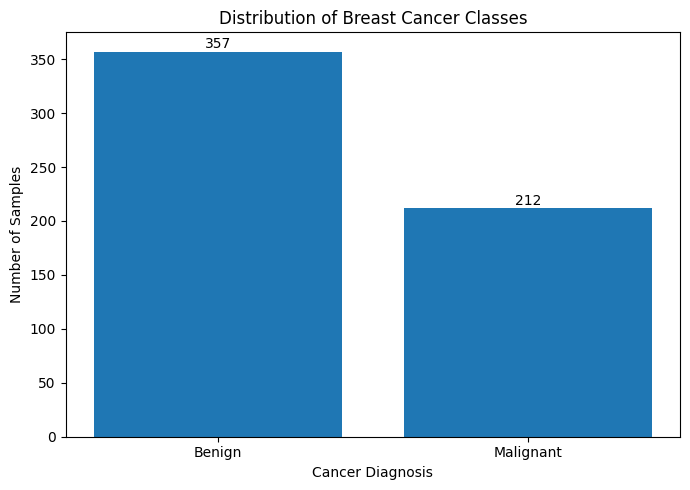

0    357
1    212
Name: count, dtype: int64


In [10]:

class_counts = pd.Series(y).value_counts().sort_index()

class_labels = ["Benign", "Malignant"]

plt.figure(figsize=(7, 5))

plt.bar(class_labels, class_counts.values)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Cancer Diagnosis")
plt.ylabel("Number of Samples")

for i, value in enumerate(class_counts.values):
    plt.text(i, value + 3, str(value), ha="center")

plt.tight_layout()
plt.show()

print(class_counts)


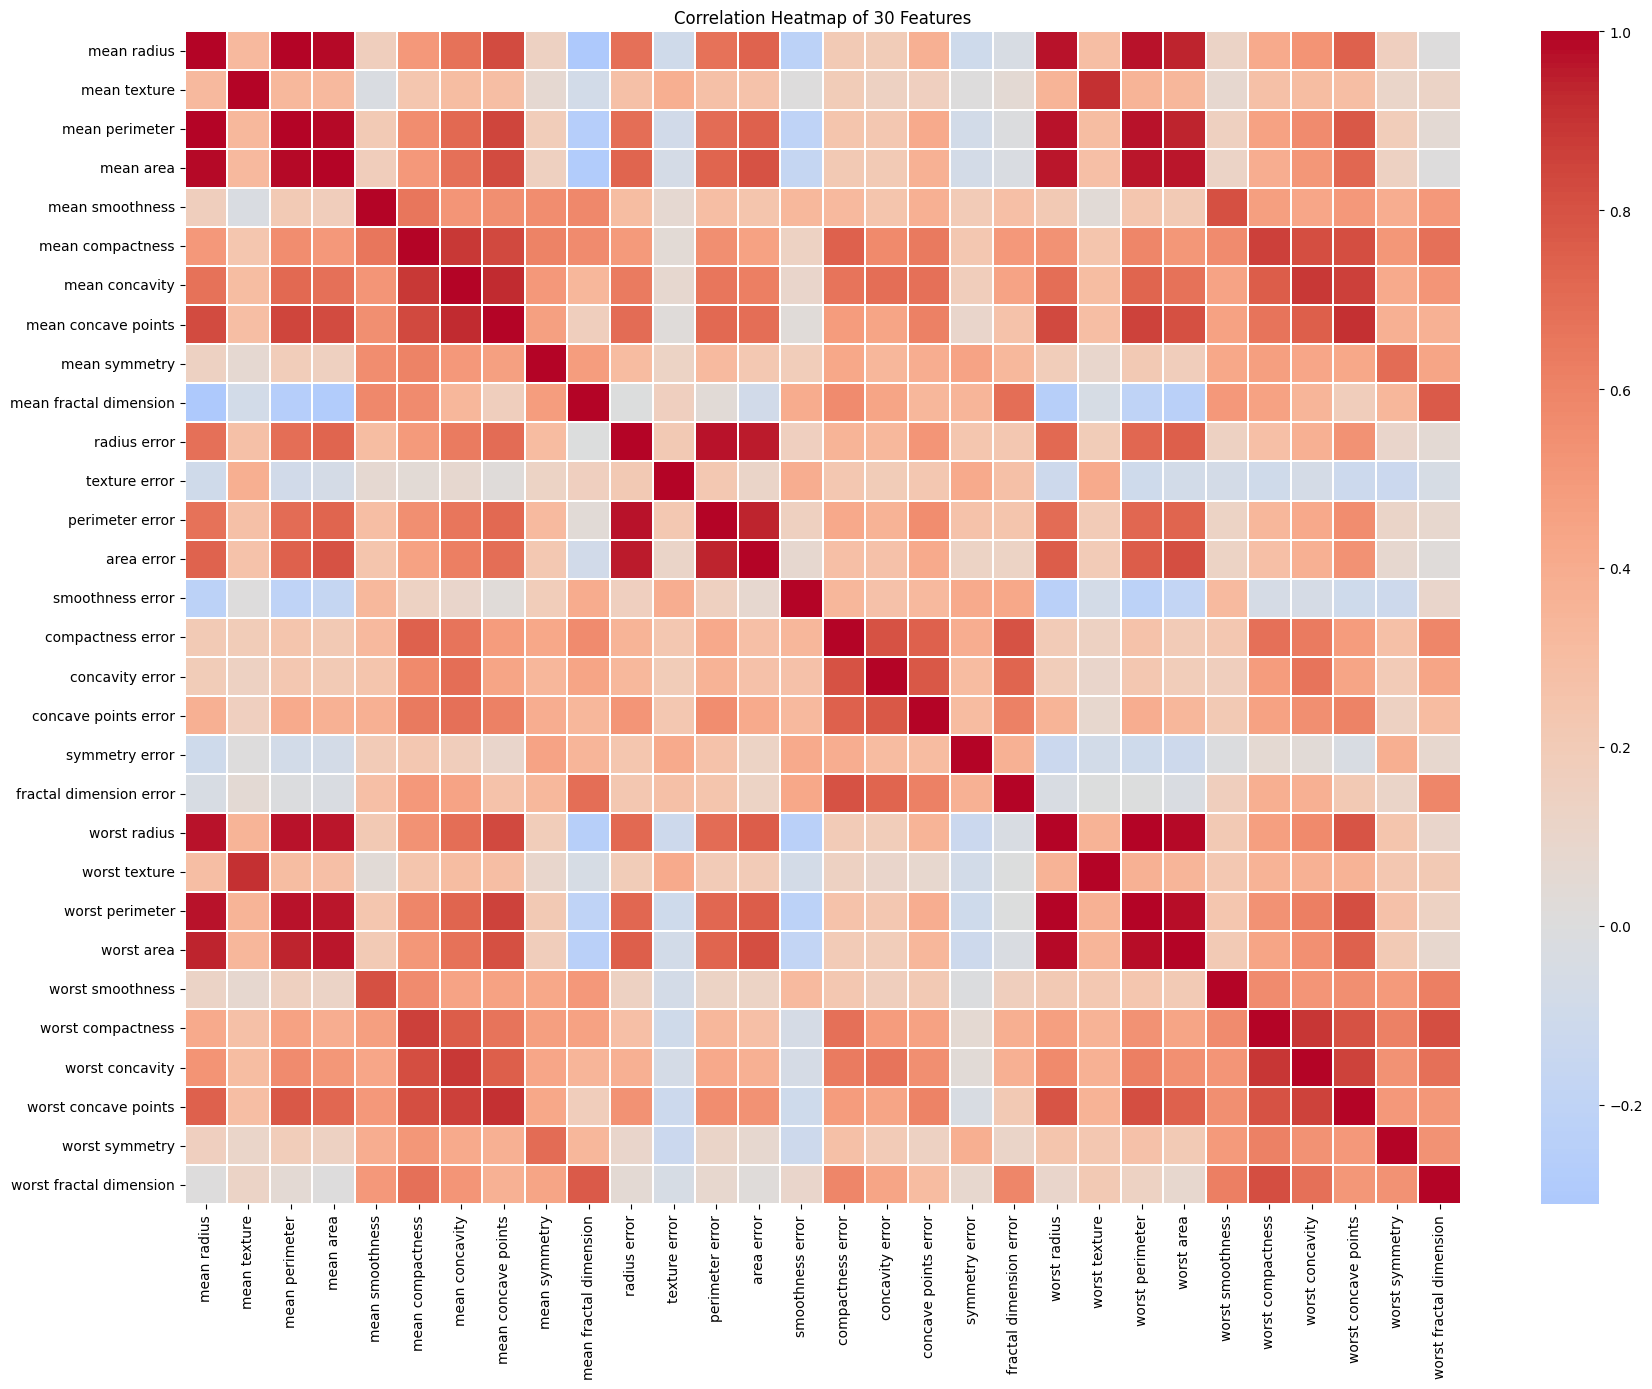

In [8]:
plt.figure(figsize=(18, 14))

correlation = X.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of 30 Features")
plt.tight_layout()
plt.show()

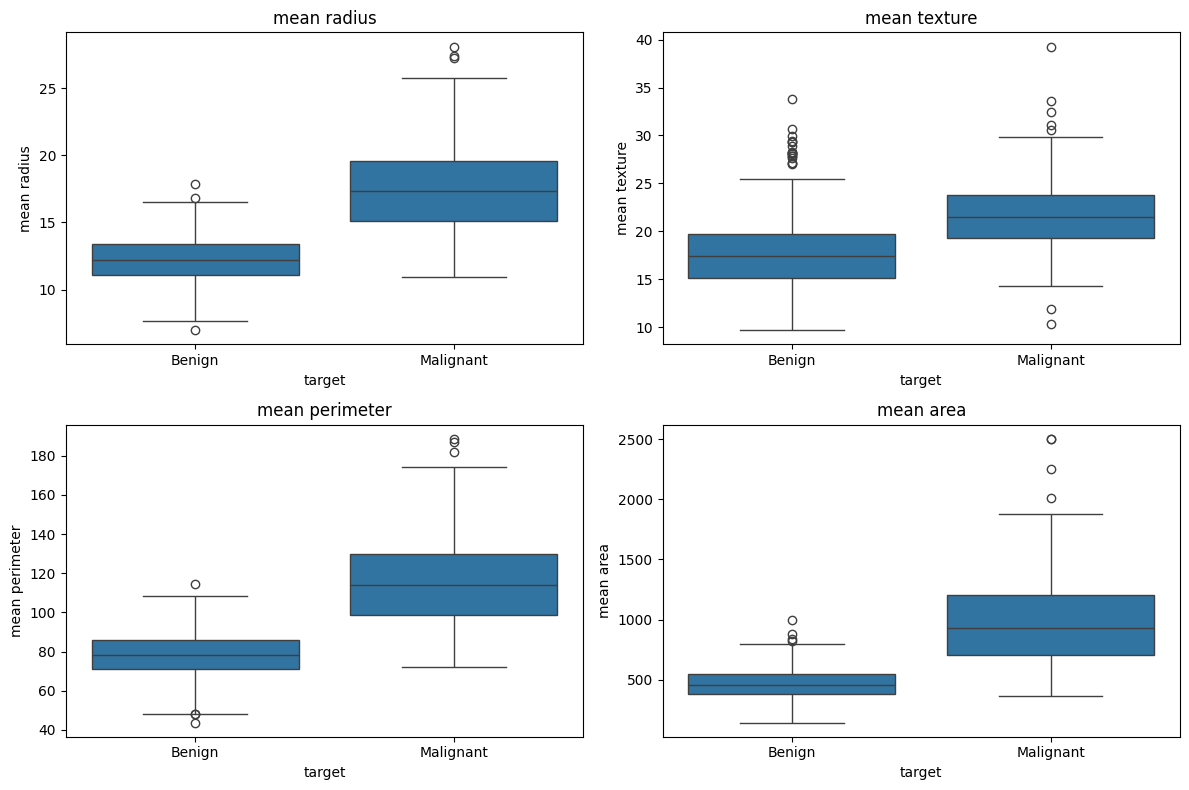

In [9]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x="target",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Benign", "Malignant"])

plt.tight_layout()
plt.show()

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


Training data shape: (455, 30)
Testing data shape: (114, 30)

Training class distribution:
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
0    72
1    42
Name: count, dtype: int64


In [12]:

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

print("Logistic Regression Pipeline created successfully!")


Logistic Regression Pipeline created successfully!


In [13]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    return_train_score=True
)

lr_grid.fit(X_train, y_train)

print("Best Parameters:")
print(lr_grid.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(lr_grid.best_score_, 4))

best_index = lr_grid.best_index_

print("\nCV Recall Mean:")
print(round(lr_grid.cv_results_["mean_test_score"][best_index], 4))

print("\nCV Recall Standard Deviation:")
print(round(lr_grid.cv_results_["std_test_score"][best_index], 4))


Best Parameters:
{'model__C': 1, 'model__class_weight': 'balanced'}

Best Cross-Validation Recall:
0.9588

CV Recall Mean:
0.9588

CV Recall Standard Deviation:
0.03


In [14]:

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1],
    "model__class_weight": [None, "balanced"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(svm_grid.best_score_, 4))

best_index = svm_grid.best_index_

print("\nCV Recall Mean:")
print(round(svm_grid.cv_results_["mean_test_score"][best_index], 4))

print("\nCV Recall Standard Deviation:")
print(round(svm_grid.cv_results_["std_test_score"][best_index], 4))


Best SVM Parameters:
{'model__C': 10, 'model__class_weight': None, 'model__gamma': 'scale'}

Best Cross-Validation Recall:
0.9647

CV Recall Mean:
0.9647

CV Recall Standard Deviation:
0.0288


In [15]:

rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__class_weight": [None, "balanced"]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(rf_grid.best_score_, 4))

best_index = rf_grid.best_index_

print("\nCV Recall Mean:")
print(round(rf_grid.cv_results_["mean_test_score"][best_index], 4))

print("\nCV Recall Standard Deviation:")
print(round(rf_grid.cv_results_["std_test_score"][best_index], 4))


Best Random Forest Parameters:
{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 300}

Best Cross-Validation Recall:
0.9471

CV Recall Mean:
0.9471

CV Recall Standard Deviation:
0.039


In [16]:

models = {
    "Logistic Regression": lr_grid,
    "SVM (RBF)": svm_grid,
    "Random Forest": rf_grid
}

comparison = []

for name, grid in models.items():
    best_index = grid.best_index_

    comparison.append({
        "Model": name,
        "Best CV Recall": round(grid.best_score_, 4),
        "CV Std": round(
            grid.cv_results_["std_test_score"][best_index], 4
        ),
        "Best Parameters": grid.best_params_
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)


,Model,Best CV Recall,CV Std,Best Parameters
0,Logistic Regression,0.9588,0.0300,"{'model__C': 1, 'model__class_weight': 'balanc..."
1,SVM (RBF),0.9647,0.0288,"{'model__C': 10, 'model__class_weight': None, ..."
2,Random Forest,0.9471,0.0390,"{'model__class_weight': None, 'model__max_dept..."


In [17]:

results = []

for name, grid in models.items():

    best_model = grid.best_estimator_

    # Predictions on test data
    y_pred = best_model.predict(X_test)

    # Probability of malignant class (class 1)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"]
    ))

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df)



Logistic Regression
Confusion Matrix:
[[71  1]
 [ 2 40]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


SVM (RBF)
Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Random Forest
Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Mali

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9954
1,SVM (RBF),0.9737,1.0000,0.9286,0.9630,0.9927
2,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9947


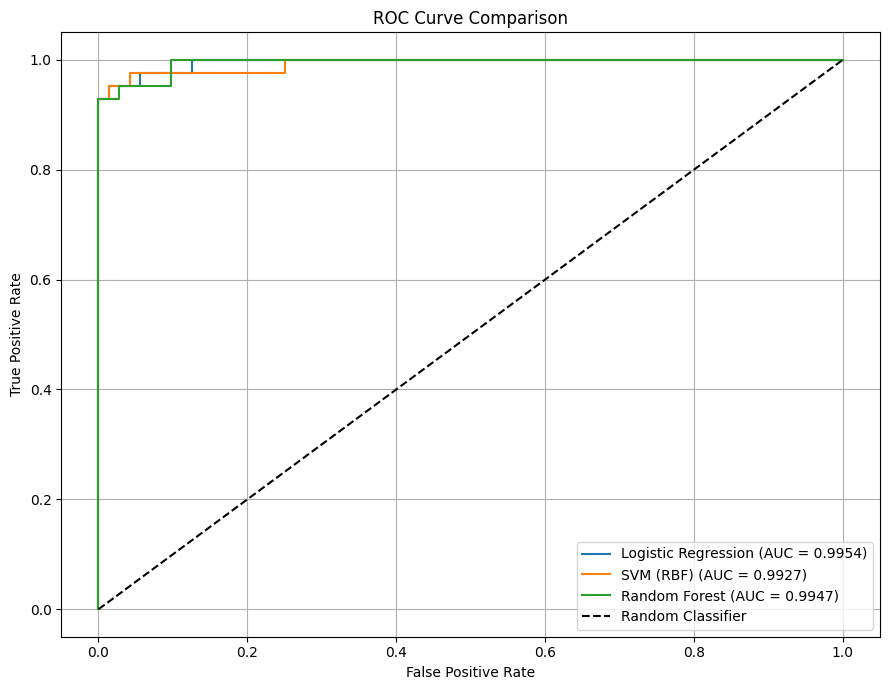

In [18]:

plt.figure(figsize=(9, 7))

for name, grid in models.items():

    best_model = grid.best_estimator_

    y_prob = best_model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


In [19]:

# Select Logistic Regression as current best candidate
best_model = lr_grid.best_estimator_

# Generate out-of-fold probabilities using training data only
oof_prob = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Find thresholds that achieve at least 95% recall
thresholds = np.arange(0.05, 0.96, 0.01)

valid_thresholds = []

for threshold in thresholds:
    predictions = (oof_prob >= threshold).astype(int)

    recall = recall_score(y_train, predictions)
    precision = precision_score(
        y_train, predictions, zero_division=0
    )

    if recall >= 0.95:
        valid_thresholds.append((threshold, recall, precision))

# Select the threshold with highest precision
best_threshold, train_recall, train_precision = max(
    valid_thresholds,
    key=lambda x: x[2]
)

print("Selected Threshold:", round(best_threshold, 2))
print("Training OOF Recall:", round(train_recall, 4))
print("Training OOF Precision:", round(train_precision, 4))


Selected Threshold: 0.57
Training OOF Recall: 0.9529
Training OOF Precision: 0.9818


In [20]:

# Get test probabilities from the selected Logistic Regression model
test_prob = best_model.predict_proba(X_test)[:, 1]

# Default threshold predictions
default_pred = (test_prob >= 0.50).astype(int)

# Selected threshold predictions
threshold_pred = (test_prob >= best_threshold).astype(int)

print("DEFAULT THRESHOLD = 0.50")
print("Precision:", round(precision_score(y_test, default_pred), 4))
print("Recall:", round(recall_score(y_test, default_pred), 4))
print("F1 Score:", round(f1_score(y_test, default_pred), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_test, default_pred))

print("\nSELECTED THRESHOLD =", best_threshold)
print("Precision:", round(precision_score(y_test, threshold_pred), 4))
print("Recall:", round(recall_score(y_test, threshold_pred), 4))
print("F1 Score:", round(f1_score(y_test, threshold_pred), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_test, threshold_pred))


DEFAULT THRESHOLD = 0.50
Precision: 0.9756
Recall: 0.9524
F1 Score: 0.9639
Confusion Matrix:
[[71  1]
 [ 2 40]]

SELECTED THRESHOLD = 0.5700000000000002
Precision: 0.975
Recall: 0.9286
F1 Score: 0.9512
Confusion Matrix:
[[71  1]
 [ 3 39]]


Top 15 Important Features:


,Feature,Importance
21,worst texture,1.466159
10,radius error,1.309001
28,worst symmetry,1.076920
7,mean concave points,0.969977
15,compactness error,0.960795
26,worst concavity,0.936887
13,area error,0.935332
23,worst area,0.905379
20,worst radius,0.901723
12,perimeter error,0.772293


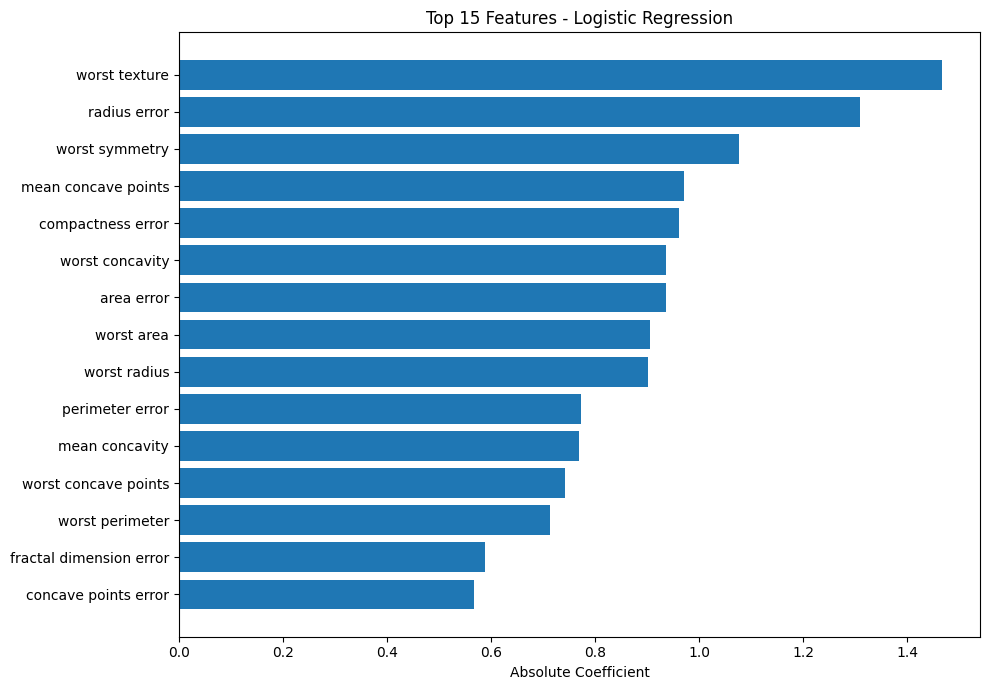

In [21]:

# Get the fitted Logistic Regression model
lr_model = best_model.named_steps["model"]

# Extract absolute coefficient values
importance = np.abs(lr_model.coef_[0])

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

# Plot top 15 features
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.title("Top 15 Features - Logistic Regression")
plt.tight_layout()
plt.show()


In [22]:

from sklearn.base import BaseEstimator, TransformerMixin

class CorrelationFilter(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.90):
        self.threshold = threshold

    def fit(self, X, y=None):
        correlation = X.corr().abs()

        upper = correlation.where(
            np.triu(
                np.ones(correlation.shape),
                k=1
            ).astype(bool)
        )

        self.drop_columns_ = [
            column for column in upper.columns
            if any(upper[column] > self.threshold)
        ]

        self.keep_columns_ = [
            column for column in X.columns
            if column not in self.drop_columns_
        ]

        return self

    def transform(self, X):
        return X[self.keep_columns_]


# Original Logistic Regression CV performance
original_scores = cross_val_score(
    lr_grid.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Reduced-feature pipeline
reduced_pipeline = Pipeline([
    ("correlation_filter", CorrelationFilter(threshold=0.90)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=lr_grid.best_params_["model__C"],
        class_weight=lr_grid.best_params_["model__class_weight"],
        max_iter=5000,
        random_state=42
    ))
])

reduced_scores = cross_val_score(
    reduced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Fit filter on complete training data to inspect selected features
feature_filter = CorrelationFilter(threshold=0.90)
feature_filter.fit(X_train)

print("Original number of features:", X_train.shape[1])
print("Remaining features:", len(feature_filter.keep_columns_))
print("Removed features:", len(feature_filter.drop_columns_))

print("\nRemoved correlated features:")
print(feature_filter.drop_columns_)

print("\nOriginal CV Recall:")
print(round(original_scores.mean(), 4))
print("Original CV Std:", round(original_scores.std(), 4))

print("\nReduced Features CV Recall:")
print(round(reduced_scores.mean(), 4))
print("Reduced CV Std:", round(reduced_scores.std(), 4))


Original number of features: 30
Remaining features: 20
Removed features: 10

Removed correlated features:
['mean perimeter', 'mean area', 'mean concave points', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concave points']

Original CV Recall:
0.9588
Original CV Std: 0.03

Reduced Features CV Recall:
0.9588
Reduced CV Std: 0.03
